In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [ ]:
df = pd.read_csv('kyphosis.csv')
df.head()

,Kyphosis,Age,Number,Start
0,absent,71,3,5
1,absent,158,3,14
2,present,128,4,5
3,absent,2,5,1
4,absent,1,4,15


In [ ]:
from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()
df["Kyphosis"] = labelencoder.fit_transform(df["Kyphosis"])
df.head(10)

,Kyphosis,Age,Number,Start
0,0,71,3,5
1,0,158,3,14
2,1,128,4,5
3,0,2,5,1
4,0,1,4,15
5,0,1,2,16
6,0,61,2,17
7,0,37,3,16
8,0,113,2,16
9,1,59,6,12


In [ ]:
X = df.iloc[:,1:]
X

,Age,Number,Start
0,71,3,5
1,158,3,14
2,128,4,5
3,2,5,1
4,1,4,15
...,...,...,...
76,157,3,13
77,26,7,13
78,120,2,13
79,42,7,6


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
print(scaler.fit(X))
X = scaler.fit_transform(X)
X

StandardScaler(copy=True, with_mean=True, with_std=True)


array([[-0.21914343, -0.65203532, -1.33790708],
       [ 1.28749437, -0.65203532,  0.51634056],
       [ 0.7679641 , -0.03068401, -1.33790708],
       [-1.41406306,  0.59066729, -2.16201714],
       [-1.43138074, -0.03068401,  0.72236808],
       [-1.43138074, -1.27338662,  0.92839559],
       [-0.39232019, -1.27338662,  1.13442311],
       [-0.80794441, -0.65203532,  0.92839559],
       [ 0.50819896, -1.27338662,  0.92839559],
       [-0.42695554,  1.21201859,  0.10428553],
       [-0.02864899,  0.59066729,  0.51634056],
       [ 1.11431761, -0.65203532,  0.92839559],
       [-1.13698025,  0.59066729, -1.95598962],
       [-1.43138074, -0.03068401,  0.10428553],
       [ 1.46067113, -0.65203532,  1.34045062],
       [-1.43138074, -0.65203532,  0.92839559],
       [-0.0979197 ,  1.21201859,  0.72236808],
       [ 1.58189486,  0.59066729,  0.31031305],
       [-0.06328435,  0.59066729,  0.92839559],
       [-0.98112117, -0.03068401, -0.51379701],
       [-1.06770955, -1.27338662,  0.928

In [ ]:
Y = df.iloc[:,0]
Y

0     0
1     0
2     1
3     0
4     0
     ..
76    1
77    0
78    0
79    1
80    0
Name: Kyphosis, Length: 81, dtype: int64

In [ ]:
from keras.layers import Dropout
from keras import regularizers
from sklearn import metrics
from keras.models import Sequential
from keras.layers import Dense
from sklearn.model_selection import StratifiedKFold

In [ ]:
import tensorflow as tf
tf.random.set_seed(42)
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
cvscores=[]
cvscore1=[]
cvscore2=[]
cvscore3=[]
cvscore4=[]
cvscore5=[]
cvscore6=[]


for train, test in kfold.split(X, Y):
    model = Sequential()
    model.add(Dense(60, input_dim=3, kernel_initializer = 'uniform', kernel_regularizer=regularizers.l2(0.0005),activation='relu'))
    model.add(Dropout(0.2))
    model.add(Dense(35, kernel_regularizer=regularizers.l2(0.0005),activation='relu'))
    model.add(Dropout(0.2))
    model.add(Dense(25, kernel_regularizer=regularizers.l2(0.0005),activation='relu'))
    model.add(Dropout(0.2))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
    model.fit(X[train], Y[train], epochs=100, batch_size=10, verbose=0)
    Accuracy = model.evaluate(X[test], Y[test], verbose=0)

    cvscores.append(Accuracy[1] * 100)
    pred=model.predict_classes(X[test])
    score1= metrics.recall_score(Y[test], pred)

    score3= metrics.precision_score(Y[test], pred)

    score4= metrics.f1_score(Y[test], pred)
    score5= metrics.roc_auc_score(Y[test], pred)
    score6= metrics.balanced_accuracy_score(Y[test], pred)

    confusion = metrics.confusion_matrix(Y[test], pred)
    TP = confusion[1, 1]
    TN = confusion[0, 0]
    FP = confusion[0, 1]
    FN = confusion[1, 0]
    score2 = TN / (TN + FP)
    cvscore1.append(score1)
    cvscore2.append(score2)
    cvscore3.append(score3)
    cvscore4.append(score4)
    cvscore5.append(score5)
    cvscore6.append(score6)


print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscores), np.std(cvscores)))
print("Recall=%.2f" % np.mean(cvscore1))
print("Specificity=%.2f" % np.mean(cvscore2))
print("Precision=%.2f" % np.mean(cvscore3))
print("F1 Score=%.2f" % np.mean(cvscore4))
print("AUC=%.2f" % np.mean(cvscore5))
print("Balanced Accuracy Score=%.2f" % np.mean(cvscore6))

/usr/local/lib/python3.7/dist-packages/tensorflow/python/keras/engine/sequential.py:450: UserWarning: `model.predict_classes()` is deprecated and will be removed after 2021-01-01. Please use instead:* `np.argmax(model.predict(x), axis=-1)`,   if your model does multi-class classification   (e.g. if it uses a `softmax` last-layer activation).* `(model.predict(x) > 0.5).astype("int32")`,   if your model does binary classification   (e.g. if it uses a `sigmoid` last-layer activation).
  warnings.warn('`model.predict_classes()` is deprecated and '
/usr/local/lib/python3.7/dist-packages/tensorflow/python/keras/engine/sequential.py:450: UserWarning: `model.predict_classes()` is deprecated and will be removed after 2021-01-01. Please use instead:* `np.argmax(model.predict(x), axis=-1)`,   if your model does multi-class classification   (e.g. if it uses a `softmax` last-layer activation).* `(model.predict(x) > 0.5).astype("int32")`,   if your model does binary classification   (e.g. if it uses

87.72% (+/- 6.66%)
Recall=0.62
Specificity=0.95
Precision=0.90
F1 Score=0.65
AUC=0.79
Balanced Accuracy Score=0.79


/usr/local/lib/python3.7/dist-packages/tensorflow/python/keras/engine/sequential.py:450: UserWarning: `model.predict_classes()` is deprecated and will be removed after 2021-01-01. Please use instead:* `np.argmax(model.predict(x), axis=-1)`,   if your model does multi-class classification   (e.g. if it uses a `softmax` last-layer activation).* `(model.predict(x) > 0.5).astype("int32")`,   if your model does binary classification   (e.g. if it uses a `sigmoid` last-layer activation).
  warnings.warn('`model.predict_classes()` is deprecated and '


In [ ]:
print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscores), np.std(cvscores)))

87.72% (+/- 6.66%)


In [ ]:
model.summary()

Model: "sequential_4"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_16 (Dense)             (None, 60)                240       
_________________________________________________________________
dropout_12 (Dropout)         (None, 60)                0         
_________________________________________________________________
dense_17 (Dense)             (None, 35)                2135      
_________________________________________________________________
dropout_13 (Dropout)         (None, 35)                0         
_________________________________________________________________
dense_18 (Dense)             (None, 25)                900       
_________________________________________________________________
dropout_14 (Dropout)         (None, 25)                0         
_________________________________________________________________
dense_19 (Dense)             (None, 1)                

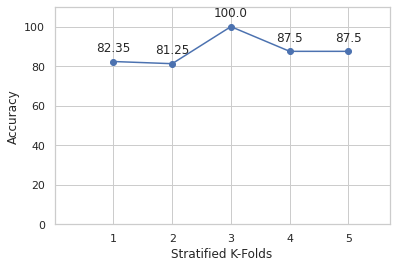

In [ ]:
t=['1','2','3','4','5']
s=cvscores
sns.set(style="whitegrid")
plt.ylim(0,110)
plt.xlim(-1,4.7)
plt.plot(t,s, marker='o')
for a,b in zip(t, s):
    label = round(b,2)
    plt.annotate(label, # this is the text
                 (a,b), # this is the point to label
                 textcoords="offset points", # how to position the text
                 xytext=(0,10), # distance from text to points (x,y)
                 ha='center')

plt.ylabel("Accuracy")
plt.xlabel("Stratified K-Folds")
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
np.random.seed(42)
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)
cvscore = []
for train, test in kfold.split(X, Y):
  classifier = DecisionTreeClassifier(criterion='gini', splitter='best',  max_depth=8)
  classifier.fit(X[train], Y[train])
  pred = classifier.predict(X[test])
  score= accuracy_score(Y[test], pred)
  print("Decision tree accuracy: %.2f%%" % (score*100))
  cvscore.append(score * 100)
print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscore), np.std(cvscore)))

Decision tree accuracy: 88.89%
Decision tree accuracy: 75.00%
Decision tree accuracy: 50.00%
Decision tree accuracy: 87.50%
Decision tree accuracy: 100.00%
Decision tree accuracy: 75.00%
Decision tree accuracy: 87.50%
Decision tree accuracy: 62.50%
Decision tree accuracy: 75.00%
Decision tree accuracy: 87.50%
78.89% (+/- 13.84%)


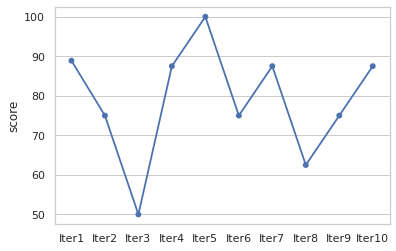

In [ ]:
scores = pd.DataFrame(cvscore,columns=['score'])

sns.set(style="whitegrid", rc={"lines.linewidth": 1})
sns.pointplot(x=['Iter1','Iter2','Iter3','Iter4','Iter5','Iter6','Iter7','Iter8','Iter9','Iter10'],y="score",data=scores)
plt.show()
sns.set()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
np.random.seed(42)
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
cvscore = []
cvscore1=[]
cvscore2=[]
cvscore3=[]
cvscore4=[]
cvscore5=[]
cvscore6=[]

for train, test in kfold.split(X, Y):
  classifier = RandomForestClassifier(n_estimators=400)
  classifier.fit(X[train], Y[train])
  pred = classifier.predict(X[test])
  score= accuracy_score(Y[test], pred)
  score1= metrics.recall_score(Y[test], pred)
  score3= metrics.precision_score(Y[test], pred)
  score4= metrics.f1_score(Y[test], pred)
  score5= metrics.roc_auc_score(Y[test], pred)
  score6= metrics.balanced_accuracy_score(Y[test], pred)

  confusion = metrics.confusion_matrix(Y[test], pred)
  TP = confusion[1, 1]
  TN = confusion[0, 0]
  FP = confusion[0, 1]
  FN = confusion[1, 0]
  score2 = TN / (TN + FP)
  cvscore.append(score * 100)
  cvscore1.append(score1)
  cvscore2.append(score2)
  cvscore3.append(score3)
  cvscore4.append(score4)
  cvscore5.append(score5)
  cvscore6.append(score6)


print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscore), np.std(cvscore)))
print("Recall=%.3f" % np.mean(cvscore1))
print("Specificity=%.3f" % np.mean(cvscore2))
print("Precision=%.3f" % np.mean(cvscore3))
print("F1 Score=%.3f" % np.mean(cvscore4))
print("AUC=%.3f" % np.mean(cvscore5))
print("Balanced Accuracy Score=%.3f" % np.mean(cvscore6))

/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


85.22% (+/- 4.85%)
Recall=0.483
Specificity=0.954
Precision=0.700
F1 Score=0.507
AUC=0.719
Balanced Accuracy Score=0.719


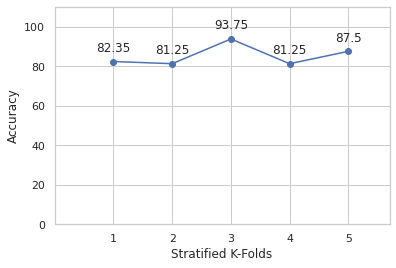

In [ ]:
t=['1','2','3','4','5']
s=cvscore
sns.set(style="whitegrid")
plt.ylim(0,110)
plt.xlim(-1,4.7)
plt.plot(t,s, marker='o')
for a,b in zip(t, s):
    label = round(b,2)
    plt.annotate(label, # this is the text
                 (a,b), # this is the point to label
                 textcoords="offset points", # how to position the text
                 xytext=(0,10), # distance from text to points (x,y)
                 ha='center')

plt.ylabel("Accuracy")
plt.xlabel("Stratified K-Folds")
plt.show()

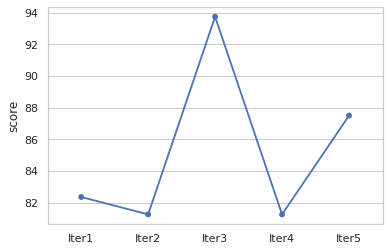

In [ ]:
scores = pd.DataFrame(cvscore,columns=['score'])

sns.set(style="whitegrid", rc={"lines.linewidth": 1})
sns.pointplot(x=['Iter1','Iter2','Iter3','Iter4','Iter5'],y="score",data=scores)
plt.show()
sns.set()

In [ ]:
from sklearn.linear_model import LogisticRegression
np.random.seed(42)
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)
cvscore = []
for train, test in kfold.split(X, Y):
  classifier = LogisticRegression()
  classifier.fit(X[train], Y[train])
  pred = classifier.predict(X[test])
  score= accuracy_score(Y[test], pred)
  print("LR accuracy: %.2f%%" % (score*100))
  cvscore.append(score * 100)
print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscore), np.std(cvscore)))

LR accuracy: 88.89%
LR accuracy: 87.50%
LR accuracy: 87.50%
LR accuracy: 87.50%
LR accuracy: 75.00%
LR accuracy: 87.50%
LR accuracy: 75.00%
LR accuracy: 75.00%
LR accuracy: 75.00%
LR accuracy: 87.50%
82.64% (+/- 6.25%)


In [ ]:
from sklearn.svm import SVC
np.random.seed(42)
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)
cvscore = []
cvscore1=[]
cvscore2=[]
cvscore3=[]
cvscore4=[]
cvscore5=[]
cvscore6=[]

for train, test in kfold.split(X, Y):
  classifier = SVC(C=8, gamma=0.1, kernel='rbf')
  classifier.fit(X[train], Y[train])
  pred = classifier.predict(X[test])
  score= accuracy_score(Y[test], pred)

  score1= metrics.recall_score(Y[test], pred)
  score3= metrics.precision_score(Y[test], pred)
  score4= metrics.f1_score(Y[test], pred)
  score5= metrics.roc_auc_score(Y[test], pred)
  score6= metrics.balanced_accuracy_score(Y[test], pred)

  confusion = metrics.confusion_matrix(Y[test], pred)
  TP = confusion[1, 1]
  TN = confusion[0, 0]
  FP = confusion[0, 1]
  FN = confusion[1, 0]

  score2 = TN / (TN + FP)


  cvscore.append(score * 100)
  cvscore1.append(score1)
  cvscore2.append(score2)
  cvscore3.append(score3)
  cvscore4.append(score4)
  cvscore5.append(score5)
  cvscore6.append(score6)

print("Accuracy=%.2f%% (+/- %.2f%%)" % (np.mean(cvscore), np.std(cvscore)))
print("Recall=%.3f" % np.mean(cvscore1))
print("Specificity=%.3f" % np.mean(cvscore2))
print("Precision=%.3f" % np.mean(cvscore3))
print("F1 Score=%.3f" % np.mean(cvscore4))
print("AUC=%.3f" % np.mean(cvscore5))
print("Balanced Accuracy Score=%.3f" % np.mean(cvscore6))


Accuracy=85.14% (+/- 9.40%)
Recall=0.550
Specificity=0.943
Precision=0.675
F1 Score=0.540
AUC=0.746
Balanced Accuracy Score=0.746


/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


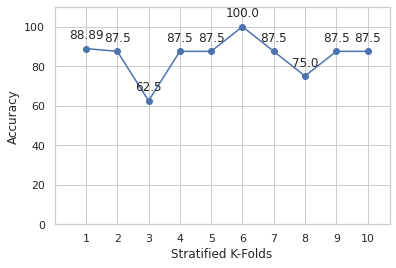

In [ ]:
t=['1','2','3','4','5','6','7','8','9','10']
s=cvscore
sns.set(style="whitegrid")
plt.ylim(0,110)
plt.xlim(-1,9.7)
plt.plot(t,s, marker='o')
for a,b in zip(t, s):
    label = round(b,2)
    plt.annotate(label, # this is the text
                 (a,b), # this is the point to label
                 textcoords="offset points", # how to position the text
                 xytext=(0,10), # distance from text to points (x,y)
                 ha='center')

plt.ylabel("Accuracy")
plt.xlabel("Stratified K-Folds")
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
np.random.seed(42)
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)
cvscore = []
cvscore1=[]
cvscore2=[]
cvscore3=[]
cvscore4=[]
cvscore5=[]
cvscore6=[]

for train, test in kfold.split(X, Y):
  classifier = KNeighborsClassifier(n_neighbors=11)
  classifier.fit(X[train], Y[train])
  pred = classifier.predict(X[test])
  score= accuracy_score(Y[test], pred)

  score1= metrics.recall_score(Y[test], pred)

  score3= metrics.precision_score(Y[test], pred)

  score4= metrics.f1_score(Y[test], pred)
  score5= metrics.roc_auc_score(Y[test], pred)
  score6= metrics.balanced_accuracy_score(Y[test], pred)


  confusion = metrics.confusion_matrix(Y[test], pred)
  TP = confusion[1, 1]
  TN = confusion[0, 0]
  FP = confusion[0, 1]
  FN = confusion[1, 0]
  score2 = TN / (TN + FP)
  cvscore.append(score * 100)
  cvscore1.append(score1)
  cvscore2.append(score2)
  cvscore3.append(score3)
  cvscore4.append(score4)
  cvscore5.append(score5)
  cvscore6.append(score6)

print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscore), np.std(cvscore)))
print("Recall=%.3f" % np.mean(cvscore1))
print("Specificity=%.3f" % np.mean(cvscore2))
print("Precision=%.3f" % np.mean(cvscore3))
print("F1 Score=%.3f" % np.mean(cvscore4))
print("AUC=%.3f" % np.mean(cvscore5))
print("Balanced Accuracy Score=%.3f" % np.mean(cvscore6))

84.03% (+/- 5.35%)
Recall=0.500
Specificity=0.940
Precision=0.550
F1 Score=0.463
AUC=0.720
Balanced Accuracy Score=0.720


/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


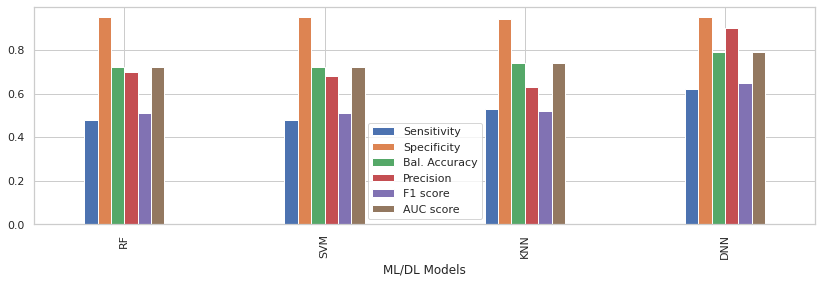

In [ ]:
# importing package
import matplotlib.pyplot as plt
import pandas as pd


# create data
df = pd.DataFrame([['RF', 0.48, 0.95, 0.72, 0.70, 0.51, 0.72], ['SVM', 0.48, 0.95, 0.72, 0.68, 0.51, 0.72], ['KNN', 0.53, 0.94, 0.74, 0.63, 0.52, 0.74],
                   ['DNN', 0.62, 0.95, 0.79, 0.90, 0.65, 0.79]],
                  columns=['ML/DL Models', 'Sensitivity', 'Specificity', 'Bal. Accuracy','Precision', 'F1 score', 'AUC score'])

# plot grouped bar chart
df.plot(x='ML/DL Models',
        kind='bar', width=0.4, figsize=(14,4),
        stacked=False)



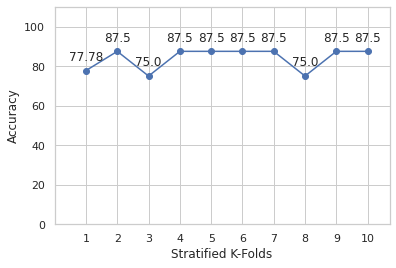

In [ ]:
t=['1','2','3','4','5','6','7','8','9','10']
s=cvscore
sns.set(style="whitegrid")
plt.ylim(0,110)
plt.xlim(-1,9.7)
plt.plot(t,s, marker='o')
for a,b in zip(t, s):
    label = round(b,2)
    plt.annotate(label, # this is the text
                 (a,b), # this is the point to label
                 textcoords="offset points", # how to position the text
                 xytext=(0,10), # distance from text to points (x,y)
                 ha='center')

plt.ylabel("Accuracy")
plt.xlabel("Stratified K-Folds")
plt.show()

In [ ]:
from sklearn.naive_bayes import GaussianNB
np.random.seed(42)
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)
cvscore = []
for train, test in kfold.split(X, Y):
  classifier = GaussianNB()
  classifier.fit(X[train], Y[train])
  pred = classifier.predict(X[test])
  score= accuracy_score(Y[test], pred)
  print("NB accuracy: %.2f%%" % (score*100))
  cvscore.append(score * 100)
print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscore), np.std(cvscore)))

NB accuracy: 88.89%
NB accuracy: 87.50%
NB accuracy: 75.00%
NB accuracy: 87.50%
NB accuracy: 75.00%
NB accuracy: 87.50%
NB accuracy: 87.50%
NB accuracy: 75.00%
NB accuracy: 75.00%
NB accuracy: 87.50%
82.64% (+/- 6.25%)


In [ ]:
outcome = []
model_names = []
models = [('LR', LogisticRegression()),
          ('DT', DecisionTreeClassifier()),
          ('RF', RandomForestClassifier(n_estimators=150)),
          ('NB', GaussianNB()),
          ('SVM',SVC(C=8, gamma=0.1, kernel='rbf')),
          ('KNN', KNeighborsClassifier(n_neighbors=11))]

In [ ]:
from sklearn import model_selection
np.random.seed(42)
for model_name, model in models:
    kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)
    results = model_selection.cross_val_score(model, X, Y, cv=kfold, scoring='accuracy')
    outcome.append(results)
    model_names.append(model_name)
    output_message = "%s| Mean=%f STD=%f" % (model_name, results.mean(), results.std())
    print(output_message)

LR| Mean=0.826389 STD=0.062500
DT| Mean=0.788889 STD=0.138444
RF| Mean=0.826389 STD=0.115244
NB| Mean=0.826389 STD=0.062500
SVM| Mean=0.851389 STD=0.094004
KNN| Mean=0.840278 STD=0.053522


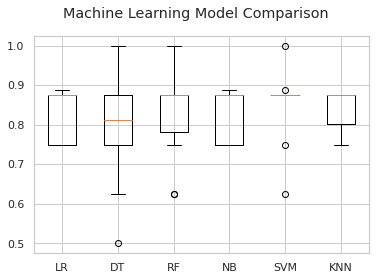

In [ ]:
fig = plt.figure()
fig.suptitle('Machine Learning Model Comparison')
ax = fig.add_subplot(111)
plt.boxplot(outcome)
ax.set_xticklabels(model_names)
plt.show()

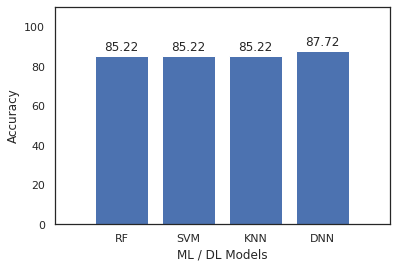

In [ ]:
cvscores1=[85.22, 85.22, 85.22, 87.72]
t=['RF', 'SVM', 'KNN', 'DNN']
s=cvscores1
sns.set(style="white")
plt.ylim(0,110)
plt.xlim(-1,4)
plt.bar(t,s)
for a,b in zip(t, s):
    label = round(b,2)
    plt.annotate(label, # this is the text
                 (a,b), # this is the point to label
                 textcoords="offset points", # how to position the text
                 xytext=(0,5), # distance from text to points (x,y)
                 ha='center')

plt.ylabel("Accuracy")
plt.xlabel("ML / DL Models")
plt.show()

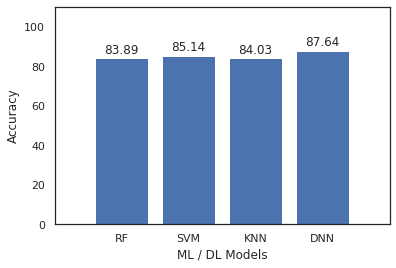

In [ ]:
cvscores2=[83.89, 85.14, 84.03, 87.64]
t=['RF', 'SVM', 'KNN', 'DNN']
s=cvscores2
sns.set(style="white")
plt.ylim(0,110)
plt.xlim(-1,4)
plt.bar(t,s)
for a,b in zip(t, s):
    label = round(b,2)
    plt.annotate(label, # this is the text
                 (a,b), # this is the point to label
                 textcoords="offset points", # how to position the text
                 xytext=(0,5), # distance from text to points (x,y)
                 ha='center')

plt.ylabel("Accuracy")
plt.xlabel("ML / DL Models")
plt.show()

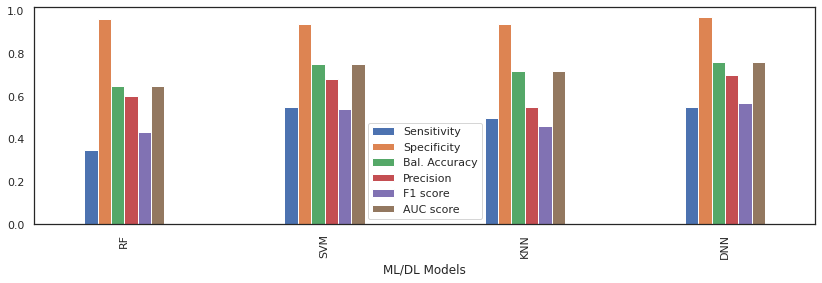

In [ ]:
# create data
df1 = pd.DataFrame([['RF', 0.35, 0.96, 0.65, 0.60, 0.43, 0.65], ['SVM', 0.55, 0.94, 0.75, 0.68, 0.54, 0.75], ['KNN', 0.50, 0.94, 0.72, 0.55, 0.46, 0.72],
                   ['DNN', 0.55, 0.97, 0.76, 0.70, 0.57, 0.76]],
                  columns=['ML/DL Models', 'Sensitivity', 'Specificity', 'Bal. Accuracy','Precision', 'F1 score', 'AUC score'])

# plot grouped bar chart
df1.plot(x='ML/DL Models',
        kind='bar', width=0.4, figsize=(14,4),
        stacked=False)